<a href="https://colab.research.google.com/github/Milu2662/BI-PYMES-ML/blob/main/notebook/06_experimental_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  BI-PYMES-ML

In [1]:
!git clone https://github.com/Milu2662/BI-PYMES-ML.git /content/BI-PYMES-ML

Cloning into '/content/BI-PYMES-ML'...
remote: Enumerating objects: 83, done.
remote: Counting objects: 100% (83/83), done.
remote: Compressing objects: 100% (71/71), done.
remote: Total 83 (delta 41), reused 28 (delta 5), pack-reused 0 (from 0)
Receiving objects: 100% (83/83), 152.49 KiB | 1.88 MiB/s, done.
Resolving deltas: 100% (41/41), done.


In [2]:
from pathlib import Path
import sys
candidates=[Path("/content/BI-PYMES-ML"),Path.cwd()]
PROJECT_DIR=next((p for p in candidates if (p/"src").exists()),Path.cwd())
if not (PROJECT_DIR/"src").exists():
    raise FileNotFoundError("No se encontró src/. Ajusta PROJECT_DIR a la raíz del repositorio.")
sys.path.insert(0,str(PROJECT_DIR))
for d in ["data/raw","data/processed","data/experimental","results/figures","results/metrics"]:
    (PROJECT_DIR/d).mkdir(parents=True,exist_ok=True)
print("Proyecto:",PROJECT_DIR)

Proyecto: /content/BI-PYMES-ML


In [4]:
from pathlib import Path
import sys
import shutil

from google.colab import drive

drive.mount("/content/drive", force_remount=True)

PROJECT_DIR = Path("/content/BI-PYMES-ML")
DRIVE_ROOT = Path("/content/drive/MyDrive")

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

# Directorios del proyecto
for d in [
    "data/raw",
    "data/processed",
    "data/experimental",
    "results/figures",
    "results/metrics"
]:
    (PROJECT_DIR / d).mkdir(parents=True, exist_ok=True)

# Recuperar archivos procesados
required_files = [
    "invoice_features.pkl",
    "retail_lines.pkl"
]

for filename in required_files:

    destination = PROJECT_DIR / "data/processed" / filename

    if destination.exists():
        print("Ya disponible:", filename)
        continue

    matches = list(DRIVE_ROOT.rglob(filename))

    if matches:
        source = matches[0]
        shutil.copy2(source, destination)
        print("Recuperado:", filename)
        print("Origen:", source)
    else:
        print("NO ENCONTRADO:", filename)

print("\nProyecto:", PROJECT_DIR)

Mounted at /content/drive
Recuperado: invoice_features.pkl
Origen: /content/drive/MyDrive/BI-PYMES-ML/invoice_features.pkl
Recuperado: retail_lines.pkl
Origen: /content/drive/MyDrive/BI-PYMES-ML/retail_lines.pkl

Proyecto: /content/BI-PYMES-ML


## 6. Evaluación experimental
Se inyectan anomalías sintéticas en una copia de las características por factura. Las etiquetas indican qué registros fueron alterados. Esto permite evaluar detección de alteraciones controladas, pero no equivale a validar todos los errores reales.

In [5]:
import pandas as pd
from src.experimental import run_comparison

# Verificar archivos
p = PROJECT_DIR / "data/processed/invoice_features.pkl"

if not p.exists():
    raise FileNotFoundError(
        "No se encontró invoice_features.pkl. "
        "Verifica la celda 2 y la ubicación en Drive."
    )

# Cargar características por factura
invoice = pd.read_pickle(p)

print("DATOS EXPERIMENTALES")
print("-" * 50)
print("Dimensiones:", invoice.shape)

# Crear muestra reproducible
SAMPLE_N = 30000

sample = invoice.sample(
    n=min(SAMPLE_N, len(invoice)),
    random_state=42
).reset_index(drop=True)

print("Facturas seleccionadas:", len(sample))

# Comparación
synthetic, if_res, lof_res, base_res, metrics = run_comparison(
    sample,
    contamination=0.03,
    random_state=42
)

display(metrics)

# Guardar resultados
metrics.to_csv(
    PROJECT_DIR / "results/metrics/synthetic_detection_metrics.csv",
    index=False
)

synthetic.to_csv(
    PROJECT_DIR / "data/experimental/invoices_with_synthetic_anomalies.csv",
    index=False
)

print("Evaluación sintética guardada correctamente.")

DATOS EXPERIMENTALES
--------------------------------------------------
Dimensiones: (53628, 14)
Facturas seleccionadas: 30000


/usr/local/lib/python3.13/dist-packages/sklearn/neighbors/_lof.py:322: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(


,model,precision,recall,f1,tn,fp,fn,tp
0,Isolation Forest,0.041111,0.041111,0.041111,28237,863,863,37
1,Local Outlier Factor,0.195556,0.195556,0.195556,28376,724,724,176
2,Robust Z-score,0.059440,0.813333,0.110783,17517,11583,168,732


Evaluación sintética guardada correctamente.


In [6]:
from src.kpi_calculation import kpi_sensitivity

from src.anomaly_detection import (
    fit_isolation_forest,
    fit_local_outlier_factor,
    statistical_baseline
)

# Cargar líneas transaccionales
lines_path = PROJECT_DIR / "data/processed/retail_lines.pkl"

if not lines_path.exists():
    raise FileNotFoundError(
        "No se encontró retail_lines.pkl. Verifica Google Drive."
    )

lines = pd.read_pickle(lines_path)

# Identificar las líneas de las facturas seleccionadas
selected = set(sample["InvoiceNo"].astype(str))

lines_sample = lines[
    lines["InvoiceNo"].astype(str).isin(selected)
].copy()

# Ejecutar los detectores sobre datos originales
# Isolation Forest
_, original_if, _ = fit_isolation_forest(
    sample,
    contamination=0.03,
    random_state=42
)

# LOF
_, original_lof, _ = fit_local_outlier_factor(
    sample,
    contamination=0.03,
    n_neighbors=20
)

# MAD
original_mad, _ = statistical_baseline(
    sample,
    threshold=3.5
)

# Calcular sensibilidad
sensitivity_if = kpi_sensitivity(
    lines_sample,
    original_if,
    flag_col="if_anomaly"
)

sensitivity_lof = kpi_sensitivity(
    lines_sample,
    original_lof,
    flag_col="lof_anomaly"
)

sensitivity_mad = kpi_sensitivity(
    lines_sample,
    original_mad,
    flag_col="baseline_anomaly"
)

# Consolidar
sensitivity_if["method"] = "Isolation Forest"
sensitivity_lof["method"] = "Local Outlier Factor"
sensitivity_mad["method"] = "MAD"

sensitivity_all = pd.concat(
    [sensitivity_if, sensitivity_lof, sensitivity_mad],
    ignore_index=True
)

display(sensitivity_all)

sensitivity_all.to_csv(
    PROJECT_DIR / "results/metrics/kpi_sensitivity_comparison.csv",
    index=False
)

print("Análisis de sensibilidad guardado correctamente.")

/usr/local/lib/python3.13/dist-packages/sklearn/neighbors/_lof.py:322: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(


,kpi,all_records,excluding_flagged_invoices,absolute_difference,difference_pct_of_all,method
0,records,5.969640e+05,5.119170e+05,8.504700e+04,14.246588,Isolation Forest
1,invoices,3.000000e+04,2.910000e+04,9.000000e+02,3.000000,Isolation Forest
2,customers,5.075000e+03,5.039000e+03,3.600000e+01,0.709360,Isolation Forest
3,recorded_revenue,1.103838e+07,8.503307e+06,2.535072e+06,22.965982,Isolation Forest
4,quantity_sum,6.203060e+06,4.602702e+06,1.600358e+06,25.799493,Isolation Forest
5,mean_unit_price,4.610265e+00,3.167206e+00,1.443060e+00,31.301014,Isolation Forest
6,cancellation_lines,1.095900e+04,1.039400e+04,5.650000e+02,5.155580,Isolation Forest
7,records,5.969640e+05,5.909430e+05,6.021000e+03,1.008604,Local Outlier Factor
8,invoices,3.000000e+04,2.910000e+04,9.000000e+02,3.000000,Local Outlier Factor
9,customers,5.075000e+03,5.053000e+03,2.200000e+01,0.433498,Local Outlier Factor


Análisis de sensibilidad guardado correctamente.


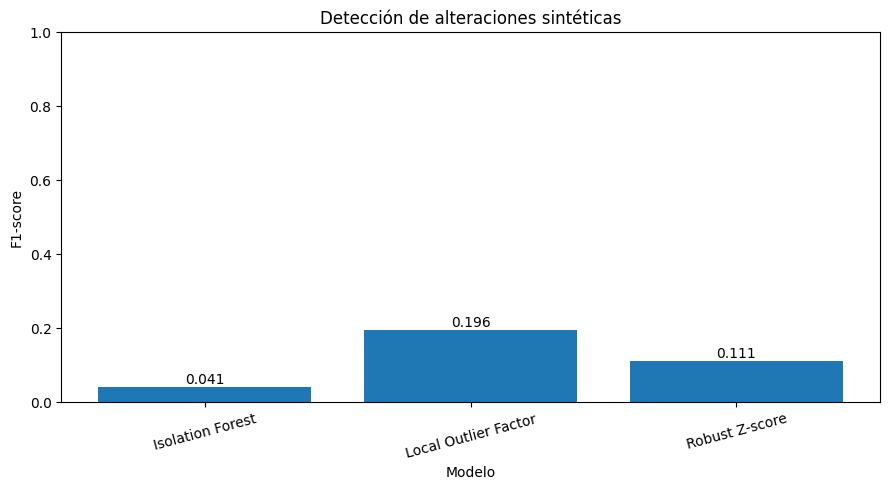

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

bars = plt.bar(metrics["model"], metrics["f1"])

plt.ylabel("F1-score")
plt.xlabel("Modelo")
plt.title("Detección de alteraciones sintéticas")

plt.ylim(0, 1)
plt.xticks(rotation=15)

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.3f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "results/figures/model_f1_comparison.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

In [8]:
# RESUMEN COMPARATIVO DE SENSIBILIDAD DE KPI

kpi_summary = sensitivity_all.pivot(
    index="kpi",
    columns="method",
    values="difference_pct_of_all"
)

display(kpi_summary.round(3))

# Guardar tabla comparativa
kpi_summary.to_csv(
    PROJECT_DIR / "results/metrics/kpi_sensitivity_summary.csv"
)

print("Resumen comparativo de KPI guardado correctamente.")

method,Isolation Forest,Local Outlier Factor,MAD
kpi,,,
cancellation_lines,5.156,9.499,42.039
customers,0.709,0.433,15.724
invoices,3.000,3.000,39.740
mean_unit_price,31.301,2.270,34.717
quantity_sum,25.799,7.739,63.103
recorded_revenue,22.966,2.317,62.093
records,14.247,1.009,55.170


Resumen comparativo de KPI guardado correctamente.
